Praktikum 1

Langkah 1

In [ ]:
# Load data
import pandas as pd
data = pd.read_csv('iris.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
data.info()
data.describe()
data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

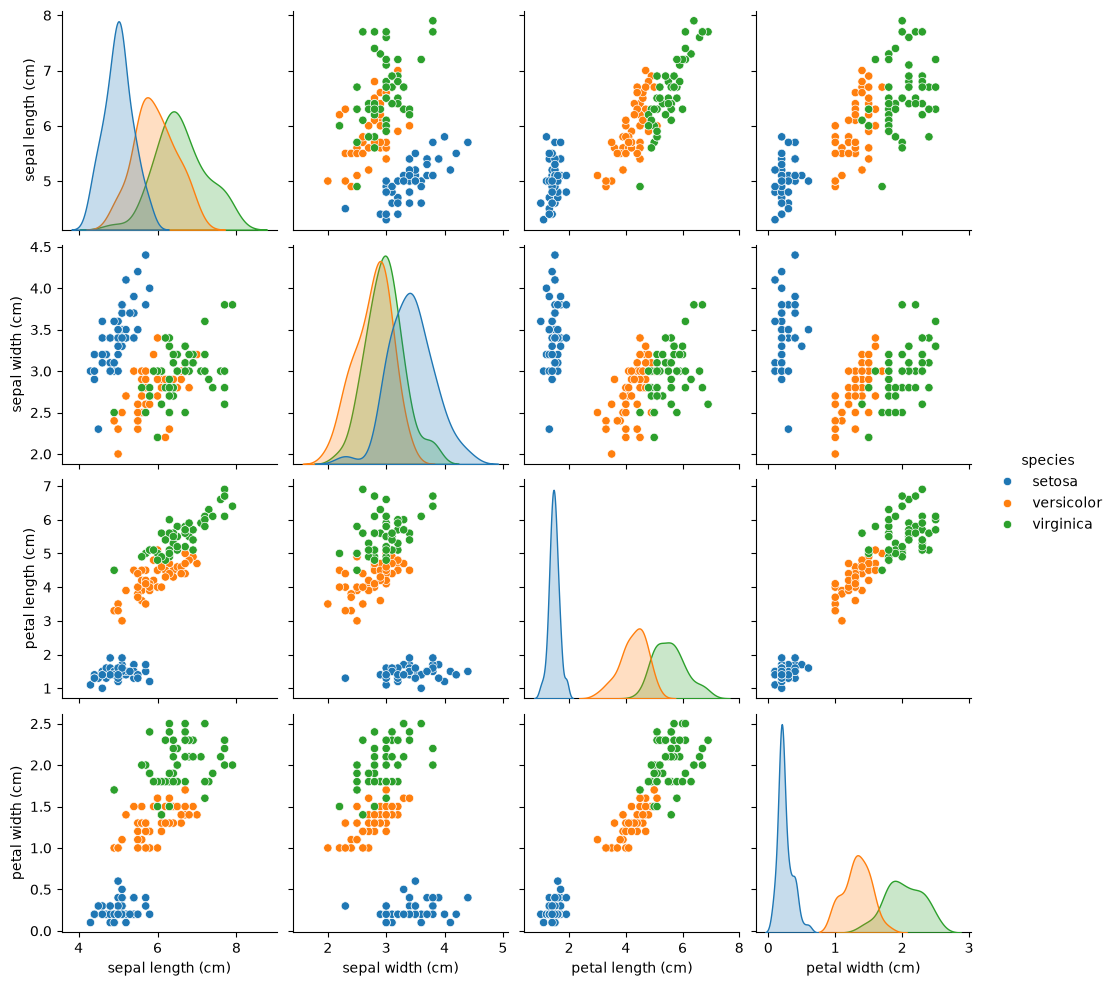

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
	
sns.pairplot(data, hue='species')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
	
X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir
	
# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
	
# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
	
# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)
	
# Latih model
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['setosa','versicolor','virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
	
y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



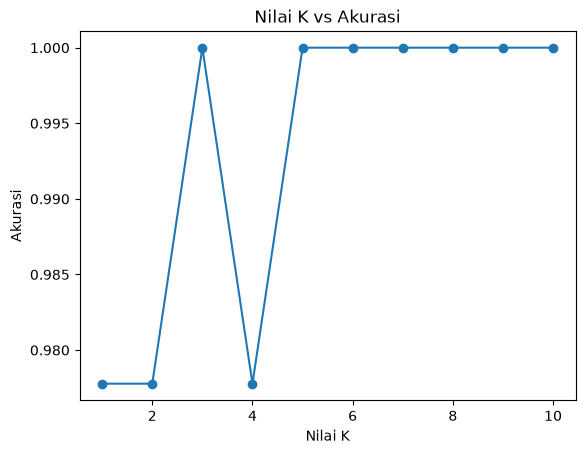

In [ ]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))
	
plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()
	

Praktikum 2

In [ ]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Secara defalt, make_classfication menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[ 34  32]
 [131 132]
 [180 185]
 [106 107]
 [ 50  49]
 [100 100]
 [ 89  86]
 [135 133]
 [107  74]
 [ 72 162]
 [ 50 145]
 [120  39]
 [146  34]
 [ 65  74]
 [ 66 170]
 [118   3]
 [ 74  78]
 [  4  46]
 [204 147]
 [133 186]
 [206  62]
 [ 66 105]
 [152  70]
 [ 73  94]
 [162  74]
 [ 73  97]
 [  3 137]
 [ 19 126]
 [ 63 146]
 [ 97 119]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Parameter yang digunakan pada fungsi make_classification adalah,

n_samples: jumlah sampel yang diinginkan

n_features: jumlah fitur yang digunakan

n_classes: jumlah kelas

n_informative: jumlah fitur yang memiliki korelasi dengan kelas

n_redundant: jumlah fitur yang tidak memiliki korelasi dengan kelas

n_repeated: jumlah fitur yang diulang

Langkah 2 (Opsional) - Membuat Data Frame

In [ ]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,34,32,0
1,131,132,0
2,180,185,0
3,106,107,0
4,50,49,0


Langkah 3 (Opsional) - Labeling

In [ ]:
# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,34,32,Kelas B
1,131,132,Kelas B
2,180,185,Kelas B
3,106,107,Kelas B
4,50,49,Kelas B


Langkah 4 - Visualisasi Data

C:\Users\User\AppData\Local\Temp\ipykernel_6340\1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
C:\Users\User\AppData\Local\Temp\ipykernel_6340\1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


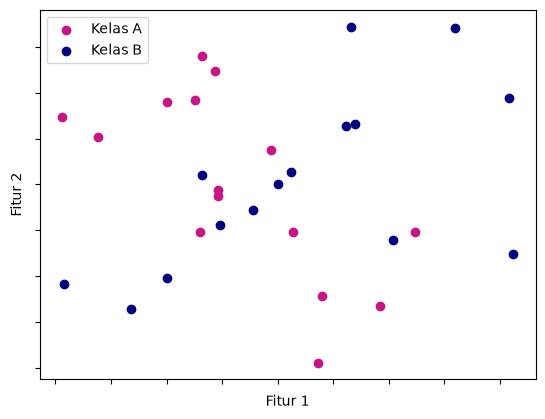

In [ ]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

Langkah 5 - Model Multinomial Naive Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Kita dapat langsung menggunakan fitur X dan label y
# hasil dari proses pembuatan data dummy

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

# Fit model
# Label y harus dalam bentuk 1D atau (n_samples,)
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.7619047619047619
Hasil akurasi data test: 0.6666666666666666


Langkah 6 - Model Gaussian Naive Bayes

In [ ]:
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.6666666666666666
Hasil akurasi data test (Gaussian): 0.3333333333333333


Praktikum 3

Langkah 1 - Load Data

In [ ]:
import numpy as np
import pandas as pd
	
df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8
	
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Langkah 2 - Preprocessing

Beberapa hal yang akan dilakukan pada tahap ini yaitu,

1. Drop kolom yang tidak digunakan

2. Ubah nama kolom v1 (label) dan v2 (teks sms)

3. Inspeksi Data

4. Encode label

5. Memisahkan fitur dengan label

Langkah 2a - Drop Kolom

In [ ]:
	# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:,2:], axis=1)
	
	# Cek data
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2b - Inspeksi Data

In [16]:
# Drop 3 kolom terakhir
df = df.drop(df.iloc[:, 2:], axis=1)

# Ubah nama kolom
df.columns = ['Labels', 'SMS']

# Cek data
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2c - Encoding Label

In [ ]:
	# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}
	# Encode label
df['Labels'] = df['Labels'].map(new_labels)	
	# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


Langkah 2d - Pisahkan Fitur dengan Label

In [ ]:
X = df['SMS'].values
y = df['Labels'].values

Langkah 3 - Ekstraksi Fitur

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
	
	# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)
	
	# Inisiasi CountVectorizer
bow = CountVectorizer()
	
	# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)
	
	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
X_test = bow.transform(X_test)

Cek fitur dari proses CountVectorizer.

In [21]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


Langkah 4 - Training dan Evaluasi Model

In [23]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

y_pred_train = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_pred_train)

y_pred_test = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_pred_test)

print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


Tugas 1

1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

Load data dan split

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('voice.csv')
df['label'] = df['label'].map({'male': 1, 'female': 0})

X = df.drop(columns='label')
y = df['label']

# Split dulu, test set baru dipakai di akhir
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(df['label'].value_counts())

label
1    1584
0    1584
Name: count, dtype: int64


1. Model kNN baseline

In [27]:
base = Pipeline([('scaler', StandardScaler()),
                 ('knn', KNeighborsClassifier(n_neighbors=5))])
scores = cross_val_score(base, X_train, y_train, cv=cv)
print(f'Baseline (20 fitur): {scores.mean():.4f} ± {scores.std():.4f}')

Baseline (20 fitur): 0.9696 ± 0.0086


Dataset voice.csv berisi 3168 data dengan 20 fitur suara. Jumlah datanya seimbang (male 1584, female 1584), jadi akurasi sudah cukup untuk menilai model. Data dibagi 80% untuk training dan 20% untuk testing, dengan perbandingan male dan female yang sama di kedua bagian. Karena kNN bekerja dengan menghitung jarak, semua fitur disamakan skalanya dengan StandardScaler. Proses ini dan pemilihan fitur dimasukkan ke dalam Pipeline supaya hanya memakai data training di setiap fold, sehingga data testing tidak "bocor" ke proses training. Model awal dengan 20 fitur dan k=5 menghasilkan akurasi cross-validation 0,9696 ± 0,0086, yang dipakai sebagai pembanding.

2. Mencari fitur paling optimal

meanfun     5697.873718
IQR         1566.488204
Q25          890.387180
sp.ent       794.113490
sd           750.762545
sfm          375.206538
centroid     324.436358
meanfreq     324.436358
median       218.279695
mindom       100.408598
maxdom        96.538999
dfrange       93.040538
meandom       89.236907
mode          76.078004
maxfun        69.673401
minfun        47.370855
kurt          19.327736
Q75           11.306350
skew           3.812982
modindx        2.112229
dtype: float64
    n_fitur    mean     std
0         1  0.9408  0.0112
1         2  0.9680  0.0055
2         3  0.9736  0.0060
3         4  0.9724  0.0043
4         5  0.9775  0.0037
5         6  0.9799  0.0032
6         7  0.9779  0.0032
7         8  0.9791  0.0043
8         9  0.9763  0.0060
9        10  0.9787  0.0054
10       11  0.9759  0.0034
11       12  0.9747  0.0055
12       13  0.9736  0.0083
13       14  0.9708  0.0073
14       15  0.9732  0.0060
15       16  0.9728  0.0069
16       17  0.9720  0.0067
1

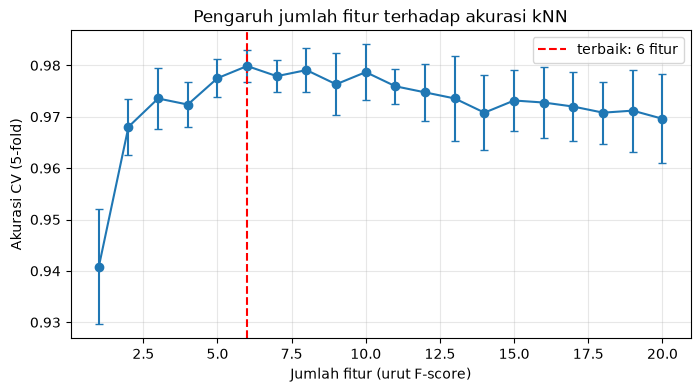

In [28]:
# Ranking fitur (hanya data training)
selector = SelectKBest(f_classif, k='all').fit(StandardScaler().fit_transform(X_train), y_train)
ranking = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
print(ranking)

# CV accuracy untuk top-n fitur
results = []
for n in range(1, X.shape[1] + 1):
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('select', SelectKBest(f_classif, k=n)),
                     ('knn', KNeighborsClassifier(n_neighbors=5))])
    s = cross_val_score(pipe, X_train, y_train, cv=cv)
    results.append((n, s.mean(), s.std()))

res = pd.DataFrame(results, columns=['n_fitur', 'mean', 'std'])
best_n = int(res.loc[res['mean'].idxmax(), 'n_fitur'])
print(res.round(4))
print('Jumlah fitur terbaik:', best_n)

plt.figure(figsize=(8, 4))
plt.errorbar(res['n_fitur'], res['mean'], yerr=res['std'], marker='o', capsize=3)
plt.axvline(best_n, color='r', ls='--', label=f'terbaik: {best_n} fitur')
plt.xlabel('Jumlah fitur (urut F-score)'); plt.ylabel('Akurasi CV (5-fold)')
plt.title('Pengaruh jumlah fitur terhadap akurasi kNN'); plt.legend(); plt.grid(alpha=.3)
plt.show()

pembanding

In [29]:
from sklearn.feature_selection import SequentialFeatureSelector

Xs = StandardScaler().fit_transform(X_train)
sfs = SequentialFeatureSelector(KNeighborsClassifier(n_neighbors=5),
                                n_features_to_select='auto', tol=0.001,
                                direction='forward', cv=cv, n_jobs=-1)
sfs.fit(Xs, y_train)
fitur_sfs = list(X.columns[sfs.get_support()])
print('Fitur terpilih (forward selection):', fitur_sfs)

Fitur terpilih (forward selection): ['IQR', 'sfm', 'mode', 'meanfun']


akurasi fitur paling tinggi dan rendah

In [30]:
# Pilih salah satu:
fitur_terpilih = list(ranking.index[:best_n])   # dari percobaan A
# fitur_terpilih = fitur_sfs                    # atau dari percobaan B
print('Fitur final:', fitur_terpilih)

Fitur final: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm']


**Fitur terbaik: meanfun, IQR, Q25, sp.ent, sd, dan sfm (6 fitur).**

Alasan:

1. **Ranking F-score:** meanfun punya skor paling tinggi (5697,87), jauh di atas IQR (1566,49) dan Q25 (890,39). Ini masuk akal karena nada suara laki-laki dan perempuan memang berbeda.
2. **Fitur yang kurang berguna:** modindx, skew, dan Q75 hampir tidak bisa membedakan suara laki-laki dan perempuan, jadi tidak dipakai.
3. **Grafik jumlah fitur:** akurasi CV naik tajam dari 1 fitur (0,941) dan paling tinggi di 6 fitur (sekitar 0,980). Setelah itu akurasinya malah turun sampai sekitar 0,970 di 20 fitur, artinya fitur tambahan hanya mengganggu perhitungan kNN.
4. **Ada fitur yang kembar:** centroid dan meanfreq punya F-score yang sama persis, jadi memakai keduanya tidak menambah informasi baru.
5. **Sejalan dengan forward selection:** metode ini memilih IQR, sfm, mode, dan meanfun. meanfun dan IQR muncul di kedua metode, jadi keduanya benar-benar fitur yang paling penting.
6. **Hasil lebih baik dan lebih ringan:** akurasi CV naik dari 0,9696 (20 fitur) menjadi sekitar 0,980 (6 fitur), dan komputasinya juga lebih ringan.

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector

Xs = StandardScaler().fit_transform(X_train)
sfs = SequentialFeatureSelector(KNeighborsClassifier(n_neighbors=5),
                                n_features_to_select='auto', tol=0.001,
                                direction='forward', cv=cv, n_jobs=-1)
sfs.fit(Xs, y_train)
fitur_sfs = list(X.columns[sfs.get_support()])
print('Fitur terpilih (forward selection):', fitur_sfs)

Fitur terpilih (forward selection): ['IQR', 'sfm', 'mode', 'meanfun']


3. Nilai k terbalik

k terbaik: 3 (akurasi CV 0.9814)


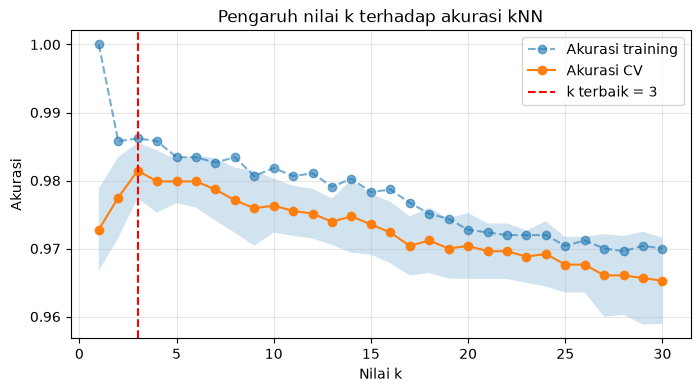

In [31]:
Xtr = X_train[fitur_terpilih]
ks = range(1, 31)
cv_mean, cv_std, train_acc = [], [], []

for k in ks:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('knn', KNeighborsClassifier(n_neighbors=k))])
    s = cross_val_score(pipe, Xtr, y_train, cv=cv)
    cv_mean.append(s.mean()); cv_std.append(s.std())
    train_acc.append(pipe.fit(Xtr, y_train).score(Xtr, y_train))

cv_mean, cv_std = np.array(cv_mean), np.array(cv_std)
best_k = list(ks)[int(np.argmax(cv_mean))]
print(f'k terbaik: {best_k} (akurasi CV {cv_mean.max():.4f})')

plt.figure(figsize=(8, 4))
plt.plot(ks, train_acc, 'o--', label='Akurasi training', alpha=.6)
plt.plot(ks, cv_mean, 'o-', label='Akurasi CV')
plt.fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, alpha=.2)
plt.axvline(best_k, color='r', ls='--', label=f'k terbaik = {best_k}')
plt.xlabel('Nilai k'); plt.ylabel('Akurasi')
plt.title('Pengaruh nilai k terhadap akurasi kNN'); plt.legend(); plt.grid(alpha=.3)
plt.show()

evaluasi akhir (hanya satu kali run setelah K terpilih)

Akurasi test: 0.9873817034700315
              precision    recall  f1-score   support

      female       0.99      0.99      0.99       317
        male       0.99      0.99      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



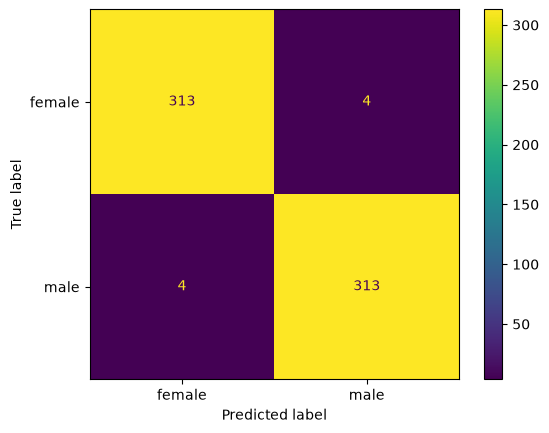

In [32]:
final = Pipeline([('scaler', StandardScaler()),
                  ('knn', KNeighborsClassifier(n_neighbors=best_k))])
final.fit(X_train[fitur_terpilih], y_train)
y_pred = final.predict(X_test[fitur_terpilih])

print('Akurasi test:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['female', 'male']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['female', 'male'])
plt.show()

**Nilai k terbaik adalah 3, dengan akurasi CV 0,9814.**

Alasan berdasarkan grafik:

1. **k terlalu kecil (k=1):** akurasi training 1,00 tetapi akurasi CV hanya sekitar 0,973. Modelnya terlalu menghafal data training karena hanya melihat 1 tetangga, jadi mudah salah pada data baru.
2. **k terlalu besar (mendekati 30):** akurasi training dan CV sama-sama turun, dengan CV sekitar 0,965. Modelnya jadi terlalu umum karena melihat terlalu banyak tetangga, sehingga data di perbatasan antar kelas sering salah.
3. **k=3 paling seimbang:** akurasi CV paling tinggi dan selisihnya dengan akurasi training kecil (0,986 dan 0,981), jadi modelnya tetap bagus pada data baru. Angka ganjil juga dipilih supaya tidak terjadi hasil seri saat voting dua kelas.
4. **Terbukti pada data test:** dengan k=3 dan 6 fitur, akurasi test mencapai 0,9873, hampir sama dengan akurasi CV.

TUGAS 2

Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

1. Menggunakan data spam.csv

2. Fitur CountVectorizer dengan mengaktifkan stop_words

3. Evaluasi hasilnya

Buatlah model klasfikasi Multinomial Naive Bayes dengan ketentuan,

1. Menggunakan data spam.csv

2. Fitur TF-IDF dengan mengaktifkan stop_words

3. Evaluasi hasilnya dan bandingkan dengan hasil pada Tugas no 2.

4. Berikan kesimpulan fitur mana yang terbaik pada kasus data spam.csv

Persiapan data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

df = pd.read_csv('spam.csv', encoding='latin-1')
df = df.iloc[:, :2]
df.columns = ['Labels', 'SMS']
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

X = df['SMS'].values
y = df['Labels'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50)

fungsi evaluasi (agar tidak menulis kode sama dua kali)

In [2]:
def evaluasi(nama, vectorizer):
    Xtr = vectorizer.fit_transform(X_train)   # fit hanya di data training
    Xte = vectorizer.transform(X_test)

    model = MultinomialNB()
    model.fit(Xtr, y_train)
    y_pred_train = model.predict(Xtr)
    y_pred = model.predict(Xte)

    print(f'=== {nama} ===')
    print('Jumlah fitur       :', Xtr.shape[1])
    print('Akurasi train      :', accuracy_score(y_train, y_pred_train))
    print('Akurasi test       :', accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['ham', 'spam'])
    plt.title(nama); plt.show()

    return {
        'Fitur': nama,
        'Jumlah fitur': Xtr.shape[1],
        'Akurasi train': accuracy_score(y_train, y_pred_train),
        'Akurasi test': accuracy_score(y_test, y_pred),
        'Precision (spam)': precision_score(y_test, y_pred),
        'Recall (spam)': recall_score(y_test, y_pred),
        'F1 (spam)': f1_score(y_test, y_pred),
    }

Soal 1: CountVectorizer + stop_words

=== CountVectorizer ===
Jumlah fitur       : 7466
Akurasi train      : 0.9946152120260264
Akurasi test       : 0.9829596412556054
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       954
        spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



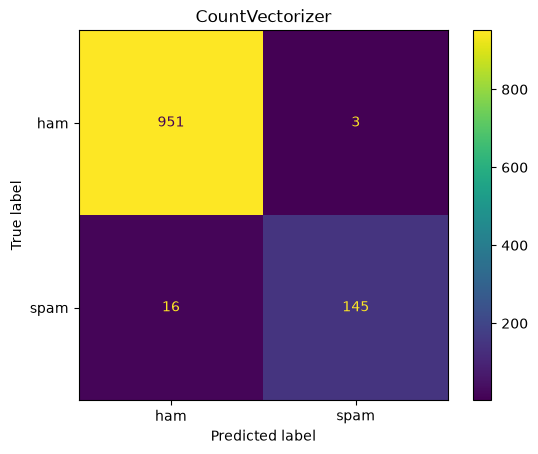

In [3]:
hasil_bow = evaluasi('CountVectorizer', CountVectorizer(stop_words='english'))

Soal 2: TF-IDF + stop_words

=== TF-IDF ===
Jumlah fitur       : 7466
Akurasi train      : 0.9842943684092439
Akurasi test       : 0.9605381165919282
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       954
        spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



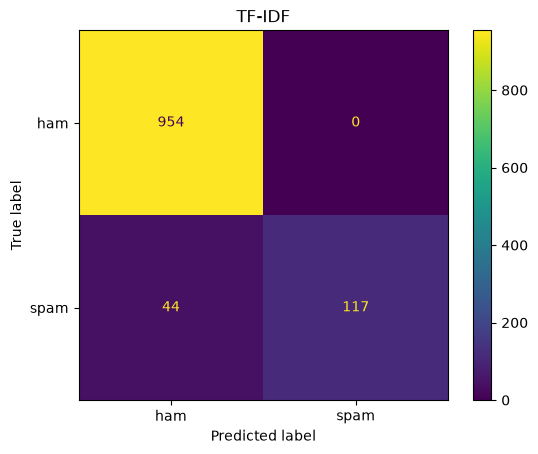

In [4]:
hasil_tfidf = evaluasi('TF-IDF', TfidfVectorizer(stop_words='english'))

Perbandingan

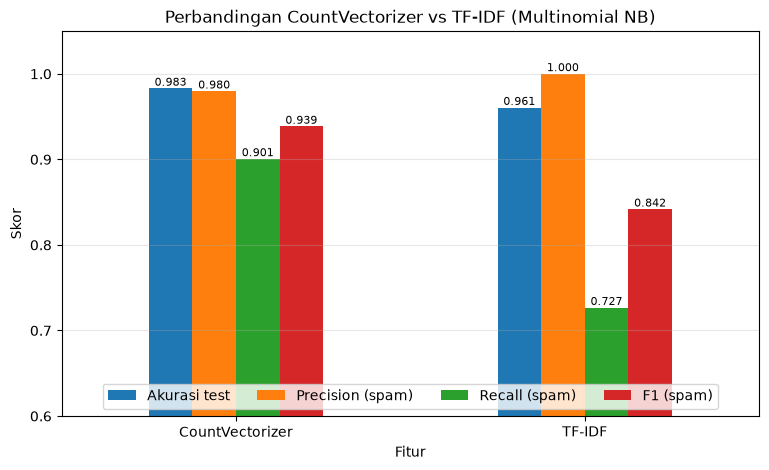

In [6]:
ax = perbandingan[['Akurasi test', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']].plot(
    kind='bar', figsize=(9, 5), ylim=(0.6, 1.05))
plt.title('Perbandingan CountVectorizer vs TF-IDF (Multinomial NB)')
plt.ylabel('Skor'); plt.xticks(rotation=0); plt.grid(axis='y', alpha=.3)
plt.legend(loc='lower center', ncol=4)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8)
plt.show()

**Tugas 2, Model 1 (CountVectorizer + stop_words)**
Pada model ini, kata-kata di SMS dihitung berapa kali muncul, dan kata umum seperti "the" dan "is" tidak dihitung. Hasilnya cukup bagus, yaitu akurasi 0,9830, precision spam 0,9797, recall spam 0,9006, dan F1 spam 0,9385. Jadi sebagian besar SMS yang ditebak spam memang benar spam, dan sekitar 90% spam berhasil terdeteksi.

**Tugas 2, Model 2 (TF-IDF + stop_words)**
Pada model ini, kata diberi nilai berdasarkan seberapa penting kata itu. Hasilnya akurasi 0,9605, precision spam 1,0000, recall spam 0,7267, dan F1 spam 0,8417. Tidak ada SMS biasa yang salah ditebak spam, tetapi masih ada sekitar 27% spam yang tidak terdeteksi.

**Perbandingan dengan CountVectorizer**
CountVectorizer lebih baik dari TF-IDF pada akurasi (0,9830 dan 0,9605), recall spam (0,9006 dan 0,7267), dan F1 spam (0,9385 dan 0,8417). TF-IDF hanya lebih baik di precision (1,0000 dan 0,9797), tetapi banyak spam yang lolos. Karena jumlah SMS biasa jauh lebih banyak daripada spam (4825 dan 747), recall dan F1 spam lebih diperhatikan daripada akurasi.

**Kesimpulan**
Fitur terbaik untuk `spam.csv` adalah **CountVectorizer**, karena hasilnya lebih seimbang dan lebih banyak spam yang berhasil terdeteksi. Multinomial Naive Bayes juga memang cocok dipakai untuk data hitungan kata.